# MODELIZACIÓN

## IMPORTAR PAQUETES

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
import os
from pathlib import Path
import openpyxl
import sqlalchemy as sa

from sklearn.feature_selection import mutual_info_regression
from sklearn.feature_selection import RFE
from xgboost import XGBRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_absolute_error

# Desactivar notación científica
pd.set_option('display.float_format', lambda x: '%.3f' % x)
np.set_printoptions(suppress=True)

#Desactivar los warnings
import warnings
warnings.filterwarnings("ignore")

# ── Rutas del proyecto ────────────────────────────────────────────────
# Se resuelven desde la ubicación del notebook, así funcionan
# igual en cualquier máquina
RAIZ = Path.cwd().parent

ORIGINALES   = RAIZ / '02_datos' / '01_Originales'
VALIDACION   = RAIZ / '02_datos' / '02_Validacion'
ENTRENAMIENTO = RAIZ / '02_datos' / '03_Entrenamiento'
CACHES       = RAIZ / '02_datos' / '04_Caches'
MODELOS      = RAIZ / '05_modelos'
RESULTADOS   = RAIZ / '06_resultados'

# ── Variables de entorno ──────────────────────────────────────────────
load_dotenv(RAIZ / '.env')

print('✅ Entorno listo')
print(f'   Raíz del proyecto: {RAIZ}')

print("✅ Librerías importadas correctamente")

✅ Entorno listo
   Raíz del proyecto: c:\Users\Admin\Desktop\Desktop\CarpetaFisica\Data Detective\Mis Casos(Importante)\PROYECTO 5 - FORECASTING RETAIL\02_FORECASTING
✅ Librerías importadas correctamente


In [2]:
x = pd.read_pickle("../02_datos/03_Entrenamiento/x_preseleccionado.pkl")
y = pd.read_pickle("../02_datos/03_Entrenamiento/y_preseleccionado.pkl")

## MODELIZANDO PARA UN PRODUCTO

In [3]:
x = x.loc[(x['store_id'] == 'CA_3') & (x['item_id'] == 'FOODS_3_586')]

In [4]:
y = y[y.index.isin(x.index )]
y

,ventas
7311,46
7312,53
7313,53
7314,79
7315,81
...,...
8355,100
8356,92
8357,63
8358,92


### MODELIZAR

#### Definir las variables de modelización

In [5]:
#Se quitan del lista porque se modelizara a nivel de producto, si se modelizara a nivel de tienda, el item_id no se excluiria,
#s i el nivel fuera a ciudad, el store_id no se excluiría, si el nivel fuera a país, ni el city_id, ni el store_id, ni el item_id
# se excluirían.
var_modelizar = x.columns.to_list()[3:] #quitando date, store_id e item_id
var_modelizar

['ventasmmp3',
 'ventasmmp4',
 'ventasmmp5',
 'ventasmmp6',
 'ventasmmp8',
 'ventasmmp2',
 'ventasmmp7',
 'ventasmmp9',
 'ventasmmp10',
 'ventasmmp11',
 'ventasmmp12',
 'ventasmmp13',
 'ventasmmp15',
 'ventasmmp14',
 'ventasmax2',
 'ventasmax8',
 'ventasmax7',
 'ventasmax6',
 'ventas_lag1',
 'ventasmax3',
 'ventasmax9',
 'ventasmax10',
 'ventasmax4',
 'ventasmax5',
 'ventasmax13',
 'ventasmax11',
 'ventasmax14',
 'ventasmin2',
 'ventasmax12',
 'ventasmax15',
 'ventasmin3',
 'ventasmin4',
 'ventasmin5',
 'ventasmin6',
 'ventasmin7',
 'ventas_lag2',
 'ventasmin8',
 'ventas_lag7',
 'ventasmin9',
 'ventas_lag6',
 'ventasmin10',
 'ventas_lag3',
 'ventasmin11',
 'ventas_lag8',
 'ventas_lag4',
 'ventasmin12',
 'ventasmin13',
 'ventas_lag5',
 'ventasmin14',
 'ventasmin15',
 'ventas_lag14',
 'ventas_lag13',
 'ventas_lag9',
 'ventas_lag15',
 'ventas_lag12',
 'ventas_lag10',
 'ventas_lag11',
 'sell_price_lag1',
 'sell_price_lag2',
 'sell_price_lag7',
 'sell_price_lag3',
 'sell_price_lag4',
 'sell

#### Definir la validación

In [6]:
#Veces a repetir el proceso mas el tamaño de la ventana de prueba (10 dias)
# Se propone que el proyecto trabaja a 10 dias de horizonte de predicción para pedidos
time_cv = TimeSeriesSplit(3, test_size = 10)

#### Crear el pipe y el diccionario de algoritmos, parámetros y validación

In [7]:
pipe = Pipeline([('algoritmo',HistGradientBoostingRegressor())])

grid = [
    {'algoritmo': [HistGradientBoostingRegressor()]
     #'algoritmo__learning_rate': [0.01,0.025,0.05,0.1],
     #'algoritmo__max_iter': [300,500,800],
     #'algoritmo__max_depth': [3,5,10]
     }
]

# Aca el algoritmo se ajustará utilizando GridSearchCV con la grilla de hiperparámetros definida, pero porque se trata de una
# modelizacion masiva, se decide no utilizar hiperparámetros y se trabajará con los valores por defecto.

#### Optimizar los hiperparámetros

##### Con random search

In [8]:
random_search = RandomizedSearchCV(estimator = pipe,
                                   param_distributions = grid,
                                   n_iter = 1, #como se trabaja con los valores por defecto, solo se realiza una iteración
                                   cv = time_cv,
                                   scoring = 'neg_mean_absolute_error',
                                   verbose = 0,
                                   n_jobs = -1)



In [9]:
modelo = random_search.fit(x[var_modelizar],y)

In [10]:
import pandas as pd

# Convierte el historial de pruebas en un DataFrame legible
cv_resultados = pd.DataFrame(random_search.cv_results_)

# Mira las columnas de los 3 folds y el promedio final:
columnas_interes = [
    'split0_test_score',  # Error en los primeros 10 días
    'split1_test_score',  # Error en los segundos 10 días
    'split2_test_score',  # Error en los terceros 10 días
    'mean_test_score',    # El promedio de los 3
    'std_test_score'      # Qué tan dispersos fueron los errores
]

print(cv_resultados[columnas_interes])
print(random_search.best_params_)
print(-random_search.best_score_)
# Te muestra el MAE promedio positivo

   split0_test_score  split1_test_score  split2_test_score  mean_test_score  \
0            -10.639            -10.866            -14.349          -11.952   

   std_test_score  
0           1.698  
{'algoritmo': HistGradientBoostingRegressor()}
11.951575445750324


In [11]:
modelo_final = modelo.best_estimator_.fit(x[var_modelizar],y)

In [12]:
prediccion = modelo_final.predict(x[var_modelizar])

## ESCALAR A TODOS LOS PRODUCTOS

### MODELIZACIÓN

Ya tenemos el proceso funcionando para modelizar un producto.

Ahora tenemos que escalarlo a todas las combinaciones de tiendas y productos.

Primero vamos a volver a importar los datos.

In [13]:
x = pd.read_pickle("../02_datos/03_Entrenamiento/x_preseleccionado.pkl")
y = pd.read_pickle("../02_datos/03_Entrenamiento/y_preseleccionado.pkl")

Incluímos como una nueva variable la combinación de tienda-producto y eliminamos las originales.

In [ ]:
x.insert(loc=0,column='producto',value=x['store_id'] + '_'+ x['item_id'])
x = x.drop(columns = ['store_id','item_id'])
x.head()

,producto,date,ventasmmp3,ventasmmp4,ventasmmp5,ventasmmp6,ventasmmp8,ventasmmp2,ventasmmp7,ventasmmp9,...,rotura_stock_7_lag1,rotura_stock_15_lag1,event_name_1_Halloween,event_type_1_Sin_evento,event_name_1_OrthodoxEaster,weekday_Monday,month_2,event_name_1_SuperBowl,event_name_1_EidAlAdha,event_name_1_Christmas
0,CA_3_FOODS_3_090,2013-01-16,201.341,212.071,218.467,222.361,226.259,183.305,224.766,227.178,...,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000
1,CA_3_FOODS_3_090,2013-01-17,196.170,203.640,209.297,213.359,218.281,188.435,216.239,219.733,...,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000
2,CA_3_FOODS_3_090,2013-01-18,183.085,190.182,196.185,200.930,207.400,176.145,204.592,209.557,...,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000
3,CA_3_FOODS_3_090,2013-01-19,203.543,203.711,205.463,207.537,211.129,208.048,209.471,212.499,...,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000
4,CA_3_FOODS_3_090,2013-01-20,282.771,267.030,257.666,251.743,244.941,310.683,247.765,242.836,...,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000


Para poder aplicar el proceso de forma recurrente vamos a crear una lista donde cada elemento sean los datos de cada producto.

In [ ]:
productos = list(x.groupby("producto"))

Encapsulamos el proceso de modelización individual en una función, a la que iremos llamando en cada producto.

In [17]:
#Recibe los datos de las x y la y de cada producto

def modelizar(x_producto, y):

    #Excluye el producto como variable de modelización
    var_modelizar = x_producto.columns.to_list()[2:]

    #Define la validación cruzada
    time_cv = TimeSeriesSplit(3, test_size = 8)

    #Define la parrilla de algoritmos
    pipe = Pipeline([('algoritmo',HistGradientBoostingRegressor())])
    grid = [
         {'algoritmo': [HistGradientBoostingRegressor()]
#          'algoritmo__learning_rate': [0.01,0.025,0.05,0.1],
#          'algoritmo__max_iter': [50,100,200],
#          'algoritmo__max_depth': [5,10,20,50],
#          'algoritmo__scoring': ['neg_mean_absolute_error'],
#          'algoritmo__l2_regularization': [0,0.25,0.5,0.75,1]
         }

    ]

    #Crea los modelos
    random_search = RandomizedSearchCV(estimator = pipe,
                                   param_distributions = grid,
                                   n_iter = 1, #cambiar segun la hiperparametrizacion
                                   cv = time_cv,
                                   scoring = 'neg_mean_absolute_error',
                                   verbose = 0,
                                   n_jobs = -1)

    modelo = random_search.fit(x_producto[var_modelizar],y)

    #Reentrena el mejor sobre todos los datos
    modelo_final = modelo.best_estimator_.fit(x_producto[var_modelizar],y)

    #Devuelve como salida el modelo final
    return(modelo_final)

Creamos otra lista vacía donde vamos a ir guardando los modelos entrenados de cada producto.

In [18]:
lista_modelos = []

In [19]:
for cada in productos:
    #Renombra por claridad
    producto = cada[0]
    datos = cada[1]
    #Selecciona solo los datos de la target que se corresponden con el producto
    y_cada = y[y.index.isin(datos.index)]

    #Llama a la funcion de modelizar
    modelo = modelizar(datos,y_cada)
    #Añade el modelo final a la lista
    lista_modelos.append((producto,modelo))


In [26]:
lista_modelos

[('CA_3_FOODS_3_090',
  Pipeline(steps=[('algoritmo', HistGradientBoostingRegressor())])),
 ('CA_3_FOODS_3_120',
  Pipeline(steps=[('algoritmo', HistGradientBoostingRegressor())])),
 ('CA_3_FOODS_3_202',
  Pipeline(steps=[('algoritmo', HistGradientBoostingRegressor())])),
 ('CA_3_FOODS_3_252',
  Pipeline(steps=[('algoritmo', HistGradientBoostingRegressor())])),
 ('CA_3_FOODS_3_288',
  Pipeline(steps=[('algoritmo', HistGradientBoostingRegressor())])),
 ('CA_3_FOODS_3_329',
  Pipeline(steps=[('algoritmo', HistGradientBoostingRegressor())])),
 ('CA_3_FOODS_3_555',
  Pipeline(steps=[('algoritmo', HistGradientBoostingRegressor())])),
 ('CA_3_FOODS_3_586',
  Pipeline(steps=[('algoritmo', HistGradientBoostingRegressor())])),
 ('CA_3_FOODS_3_587',
  Pipeline(steps=[('algoritmo', HistGradientBoostingRegressor())])),
 ('CA_3_FOODS_3_714',
  Pipeline(steps=[('algoritmo', HistGradientBoostingRegressor())])),
 ('CA_4_FOODS_3_090',
  Pipeline(steps=[('algoritmo', HistGradientBoostingRegressor())])),

Recorremos cada elemento de la lista de productos y vamos rellendando lista_modelos con el nombre y modelo final de cada producto.

Comprobamos.

NOTA: El objetivo aquí no es evaluar la calidad del modelo, ya que no estamos usando los datos de entrenamiento.

Es simplemente comprobar que el proceso funciona bien y no vemos nada raro antes de continuar.

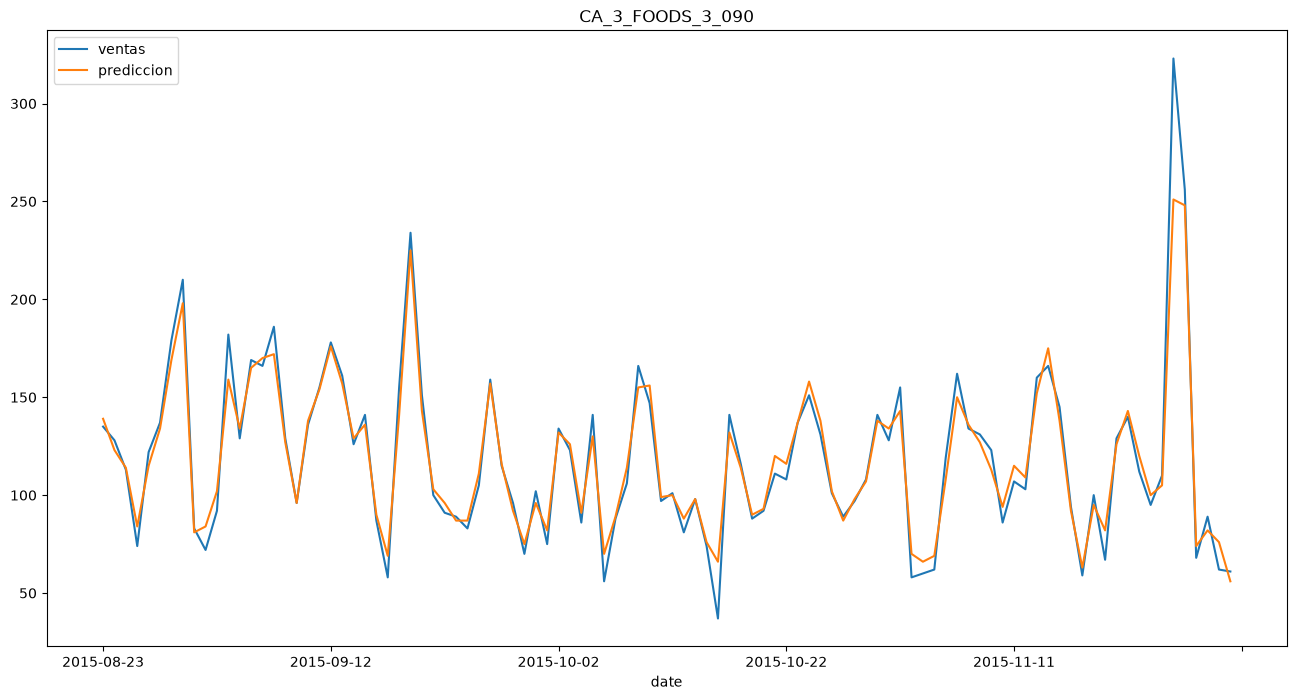

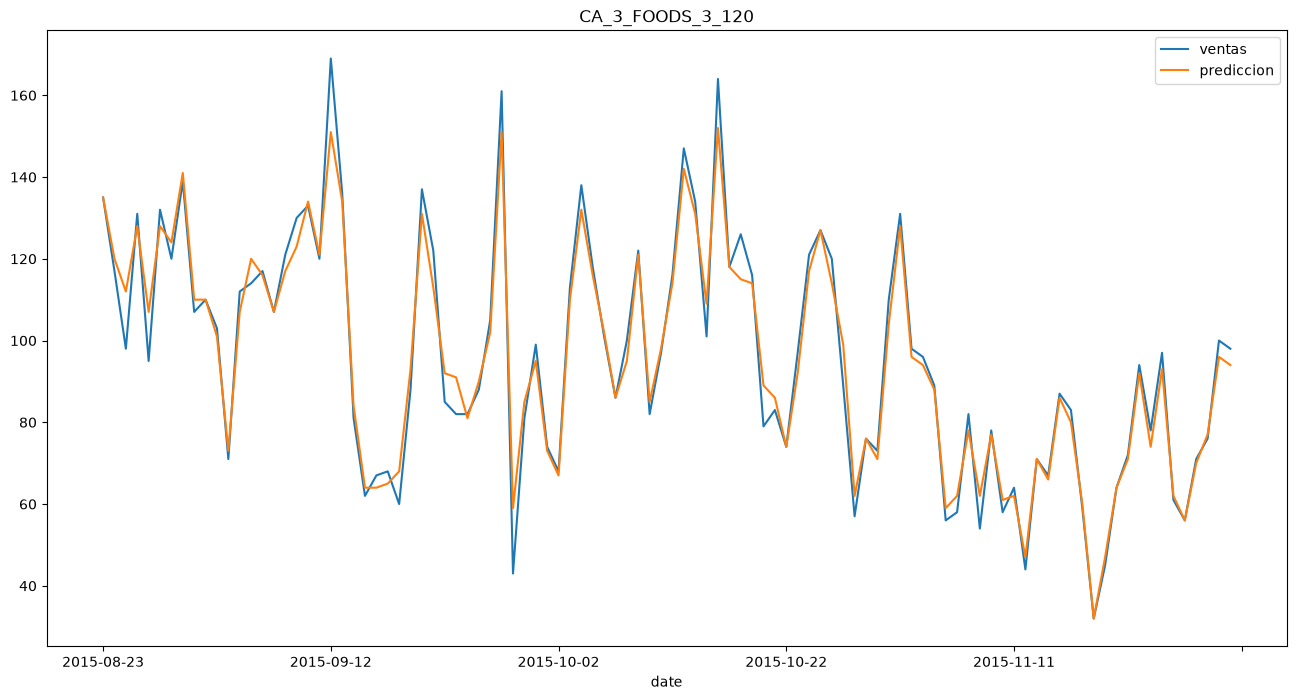

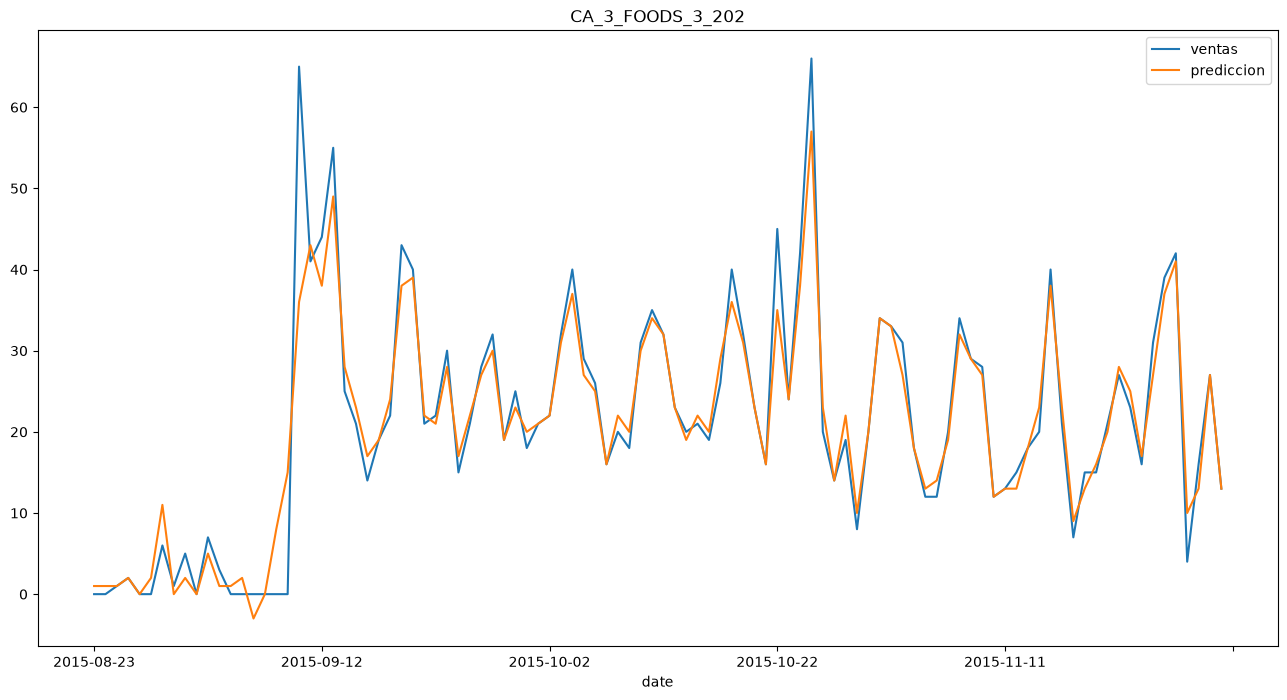

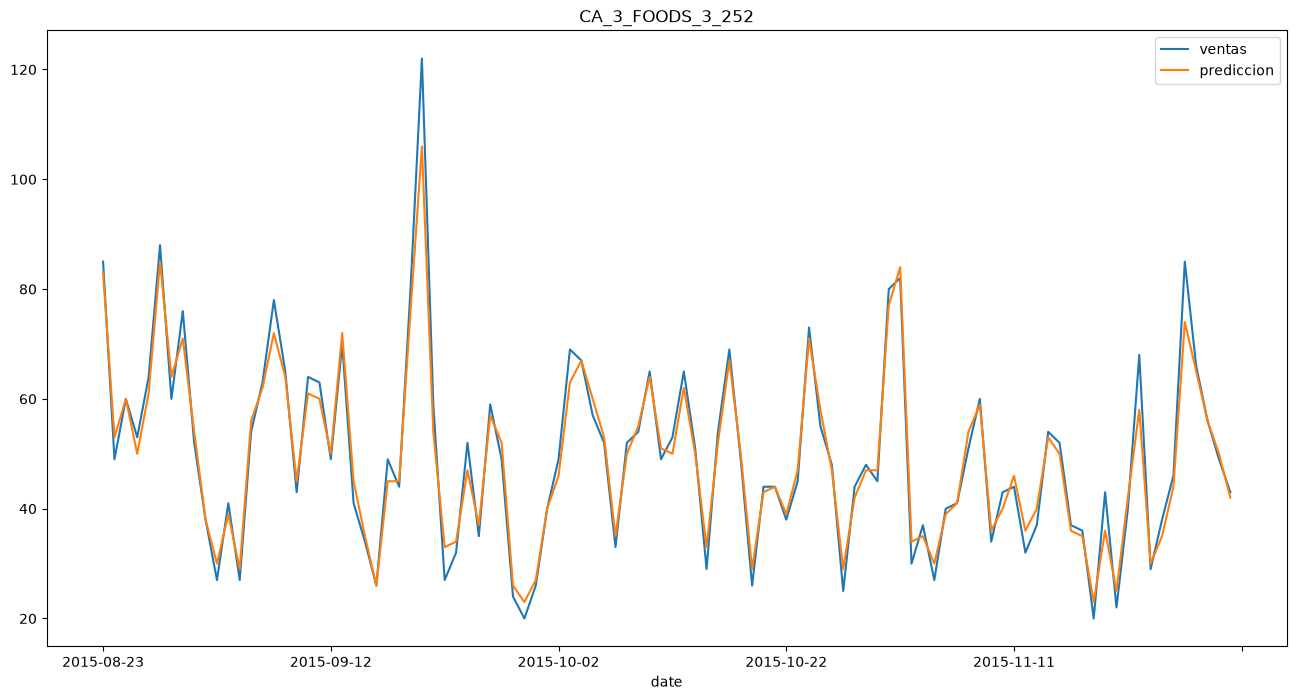

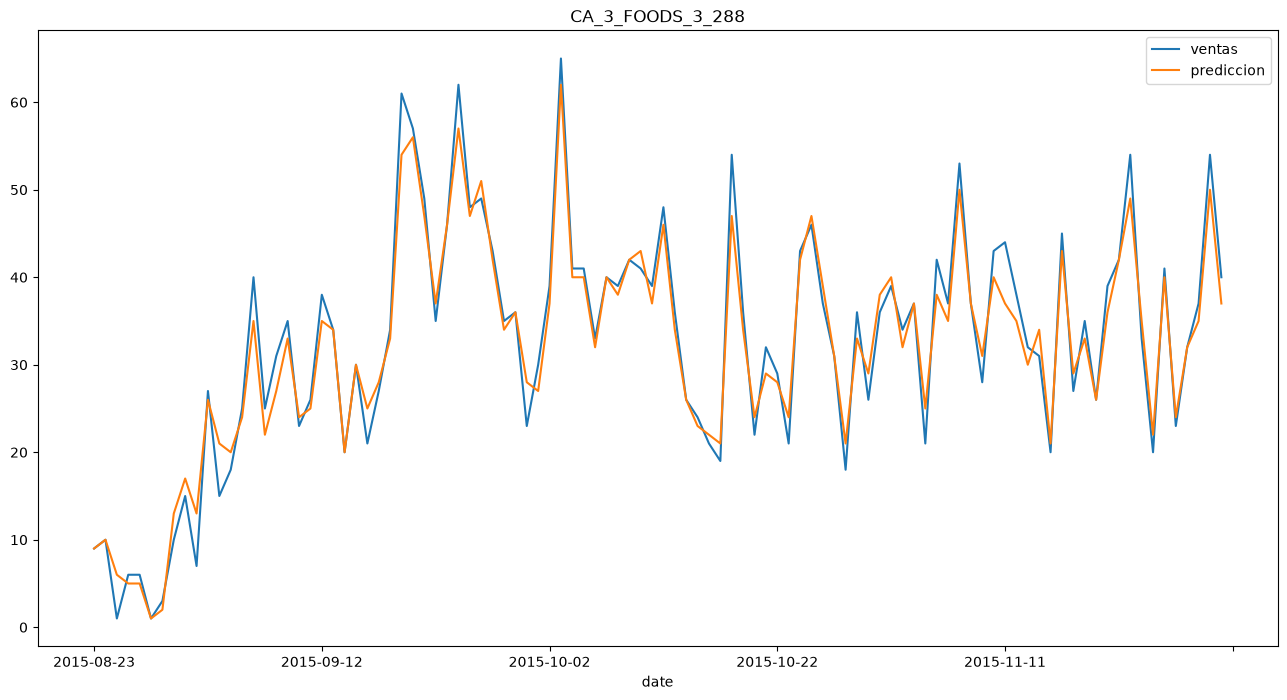

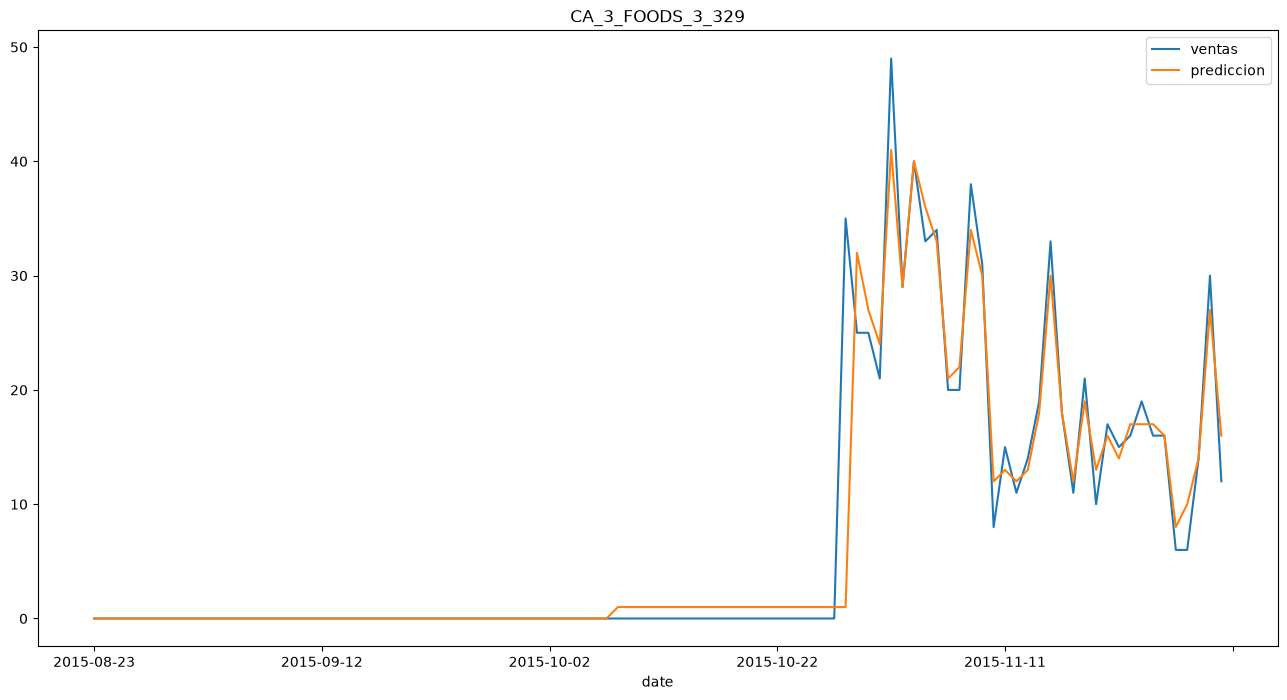

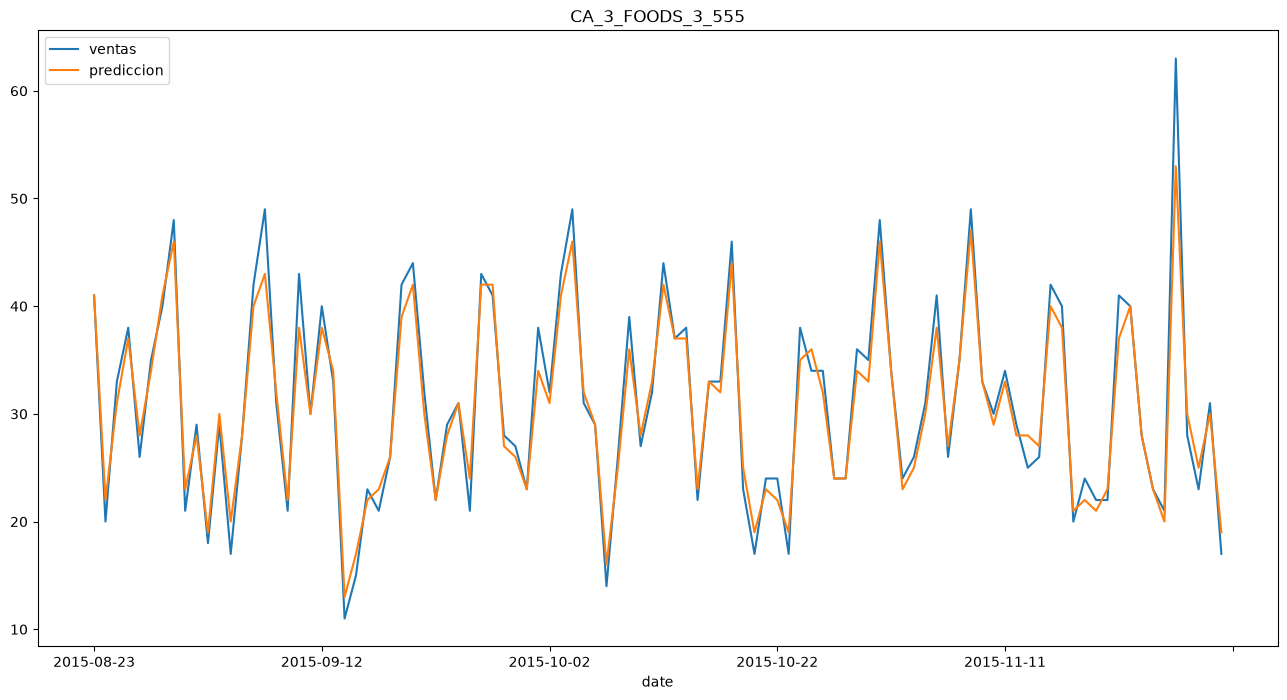

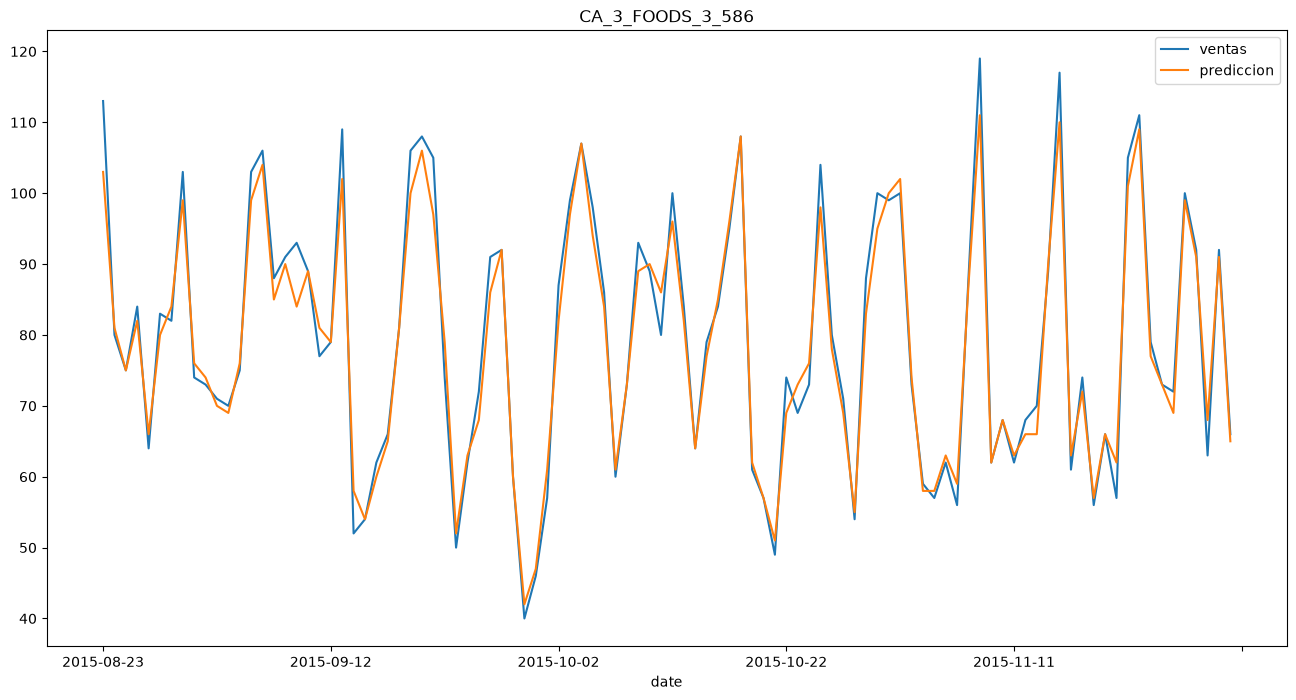

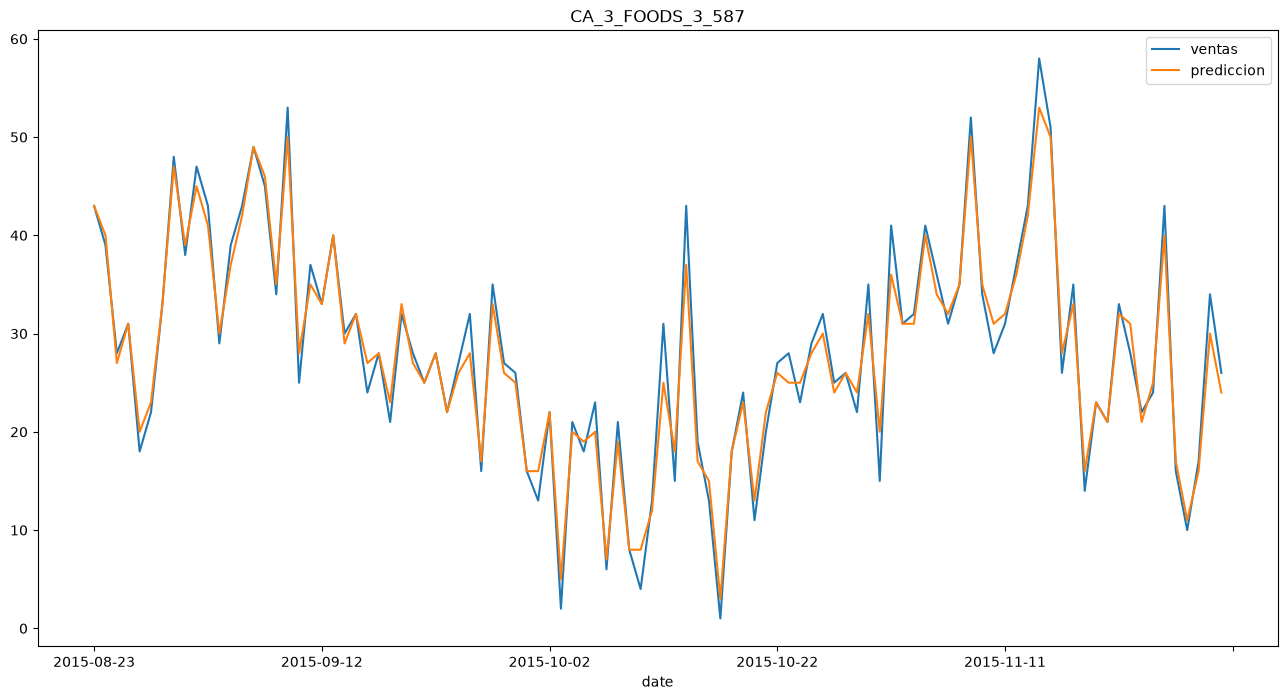

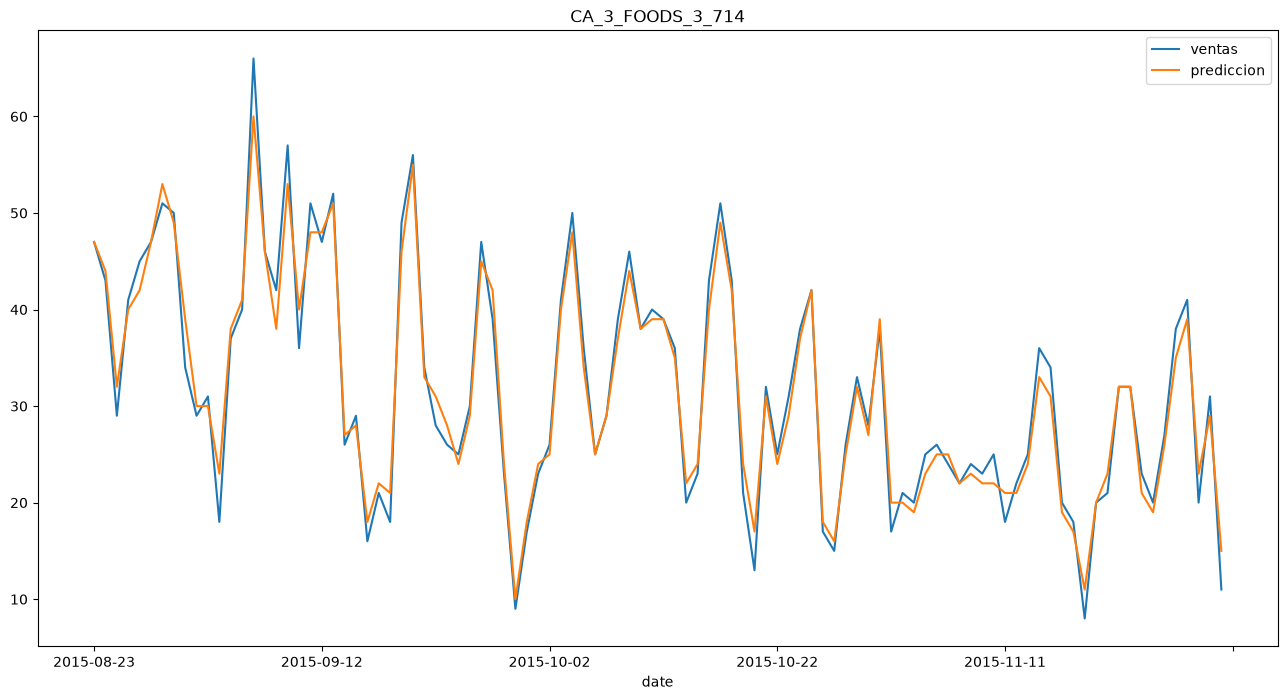

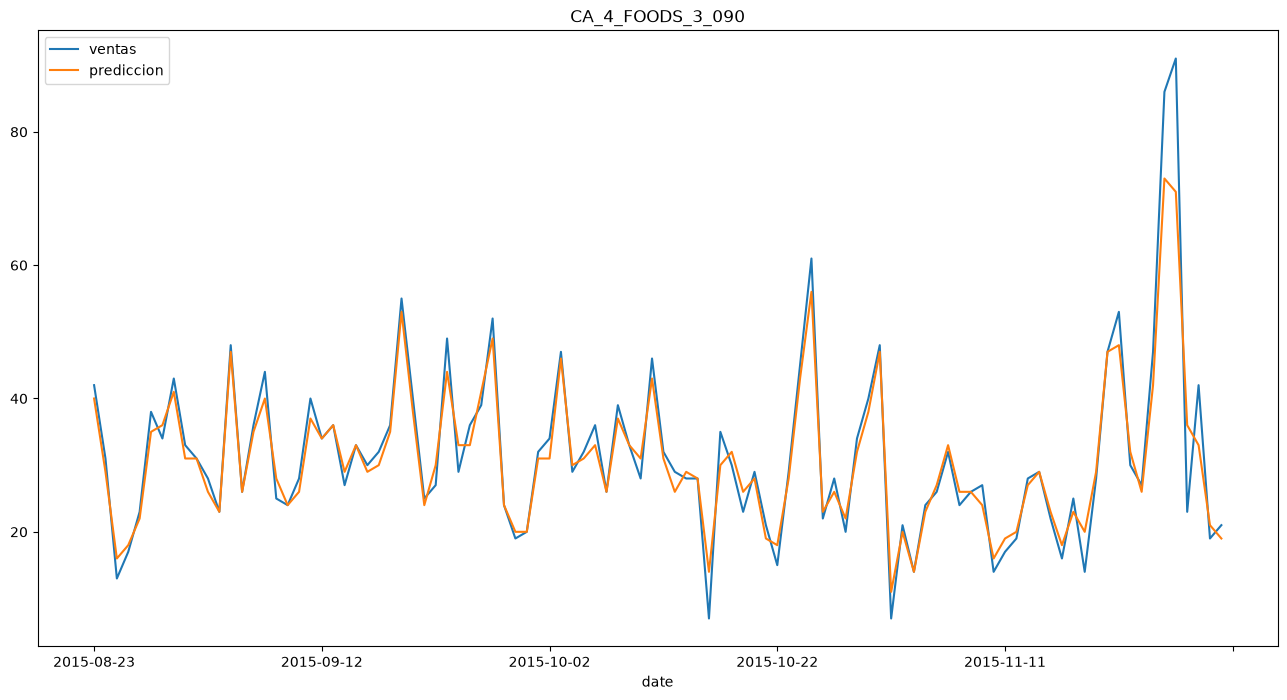

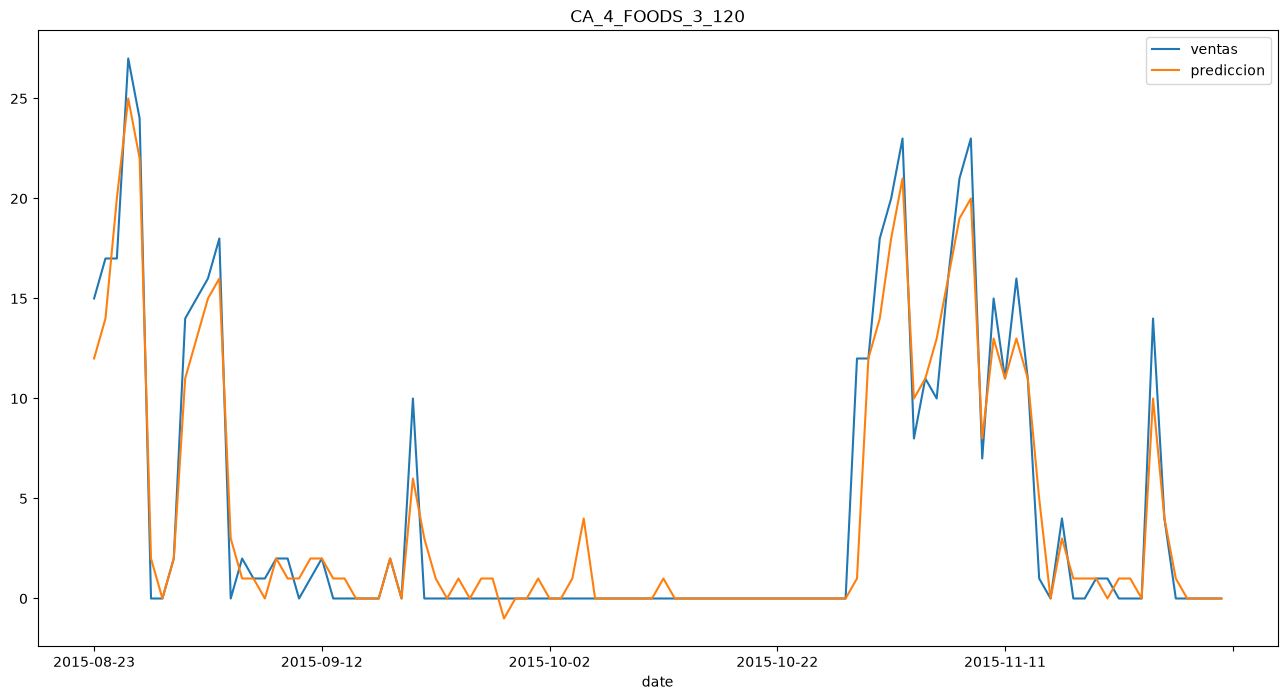

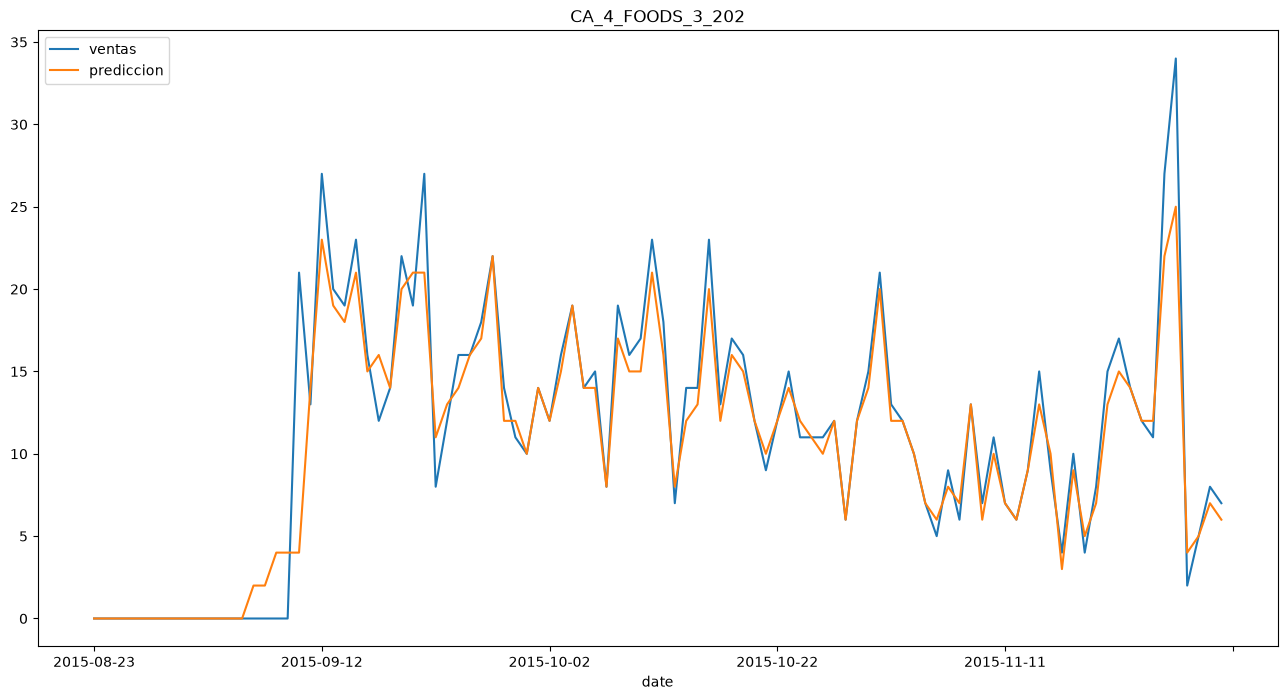

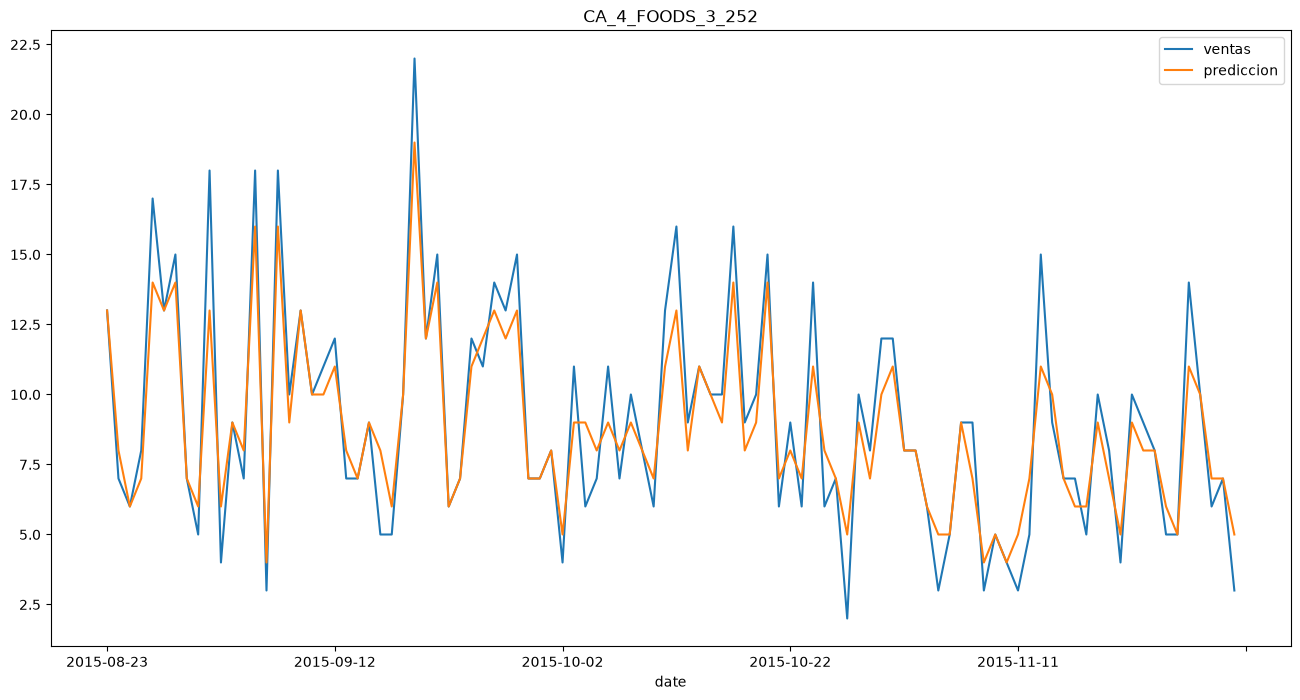

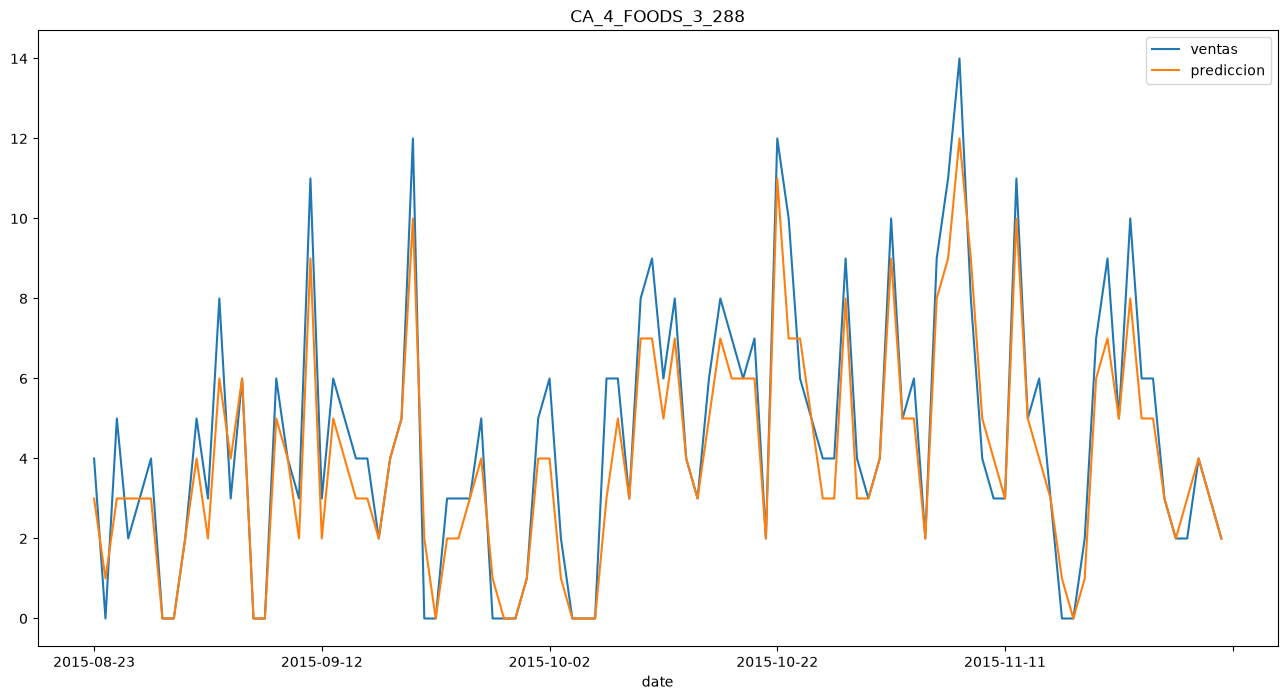

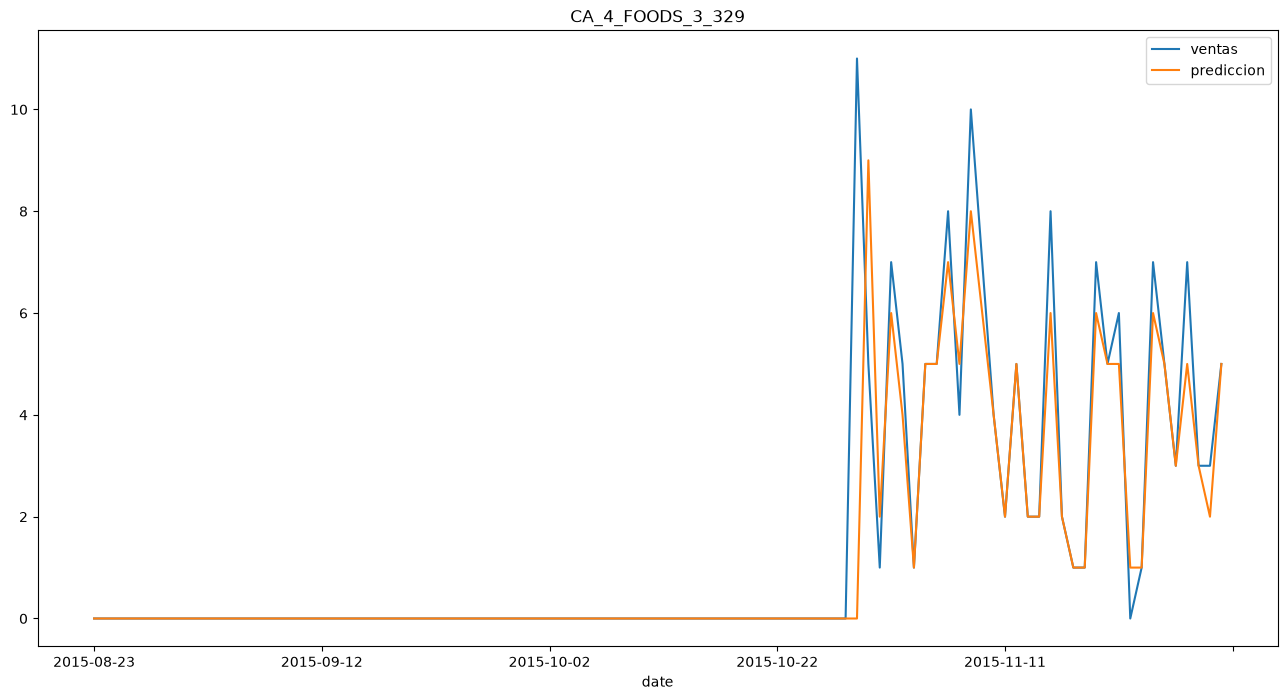

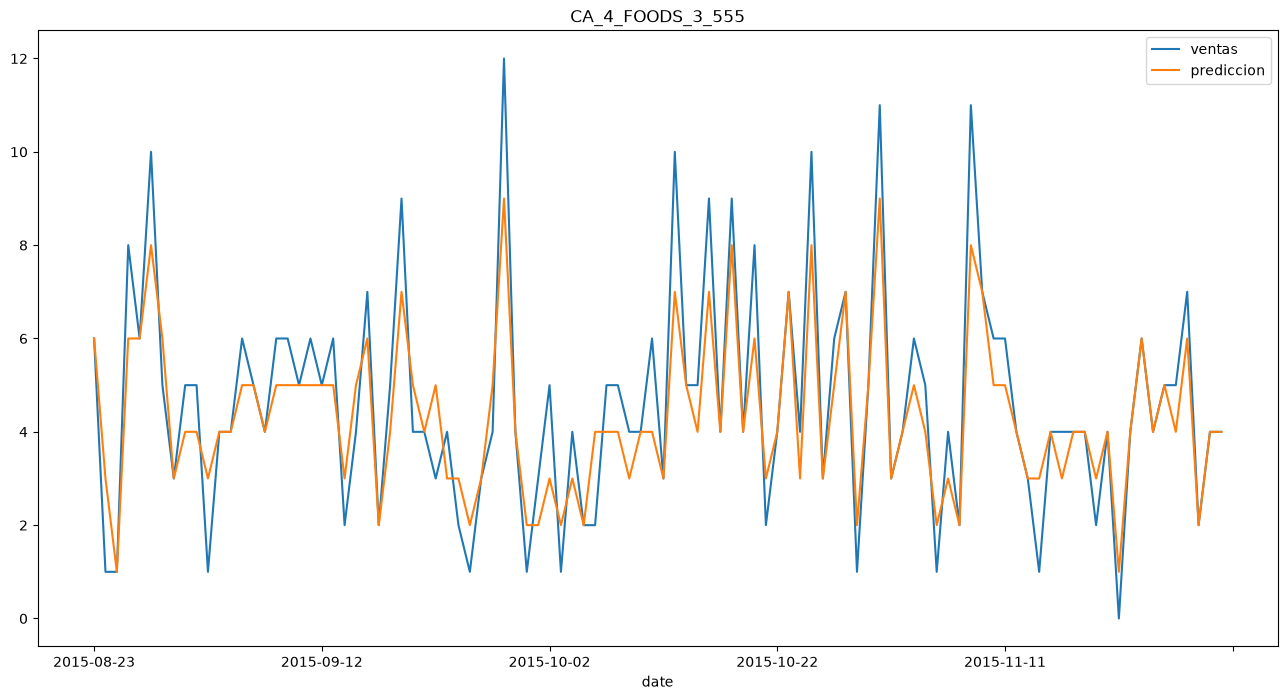

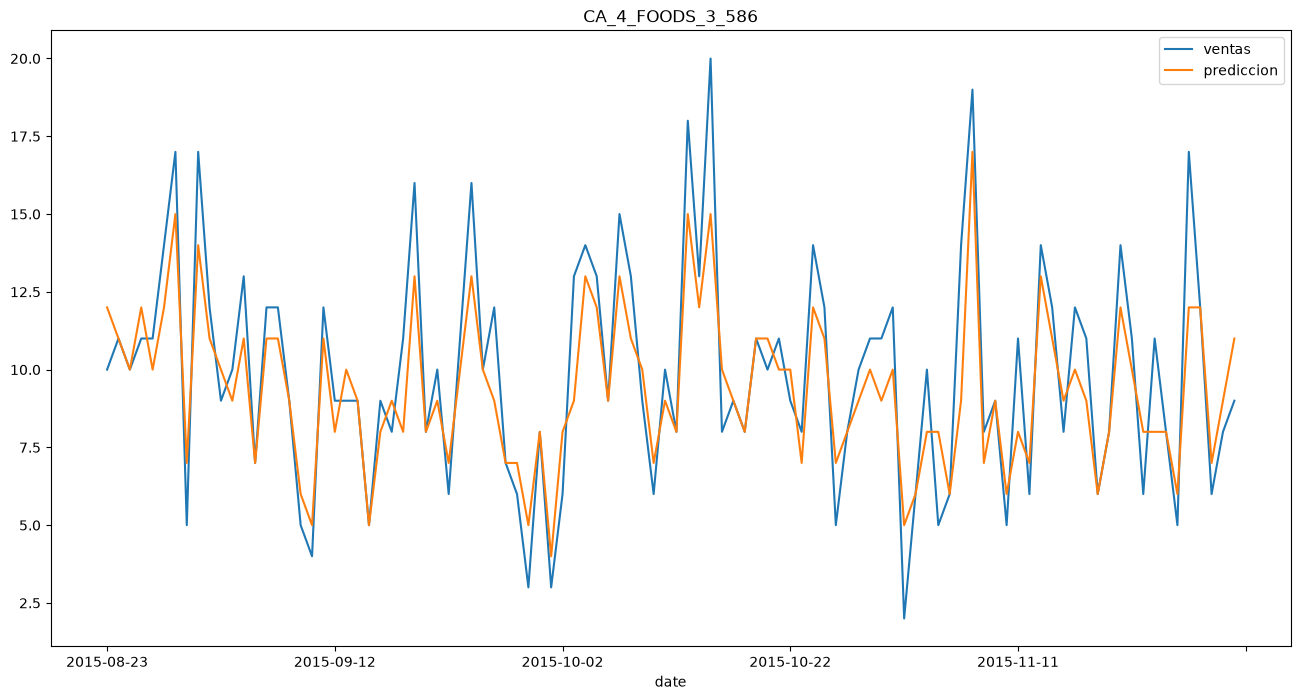

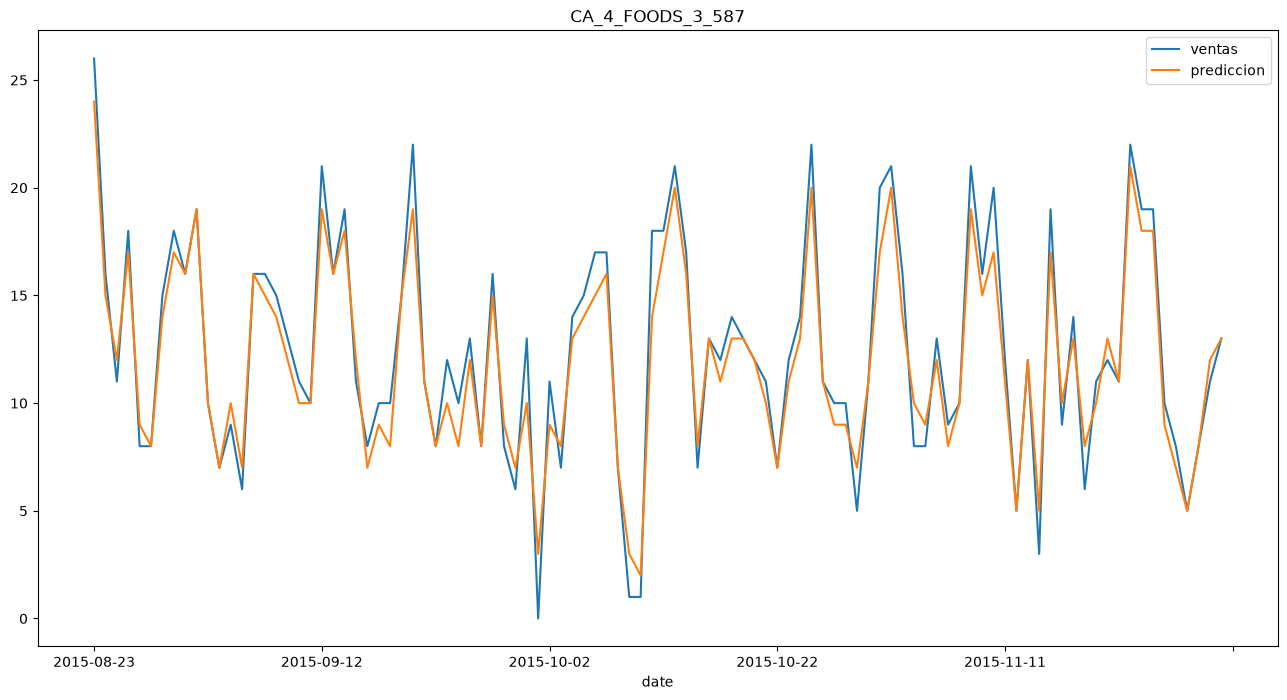

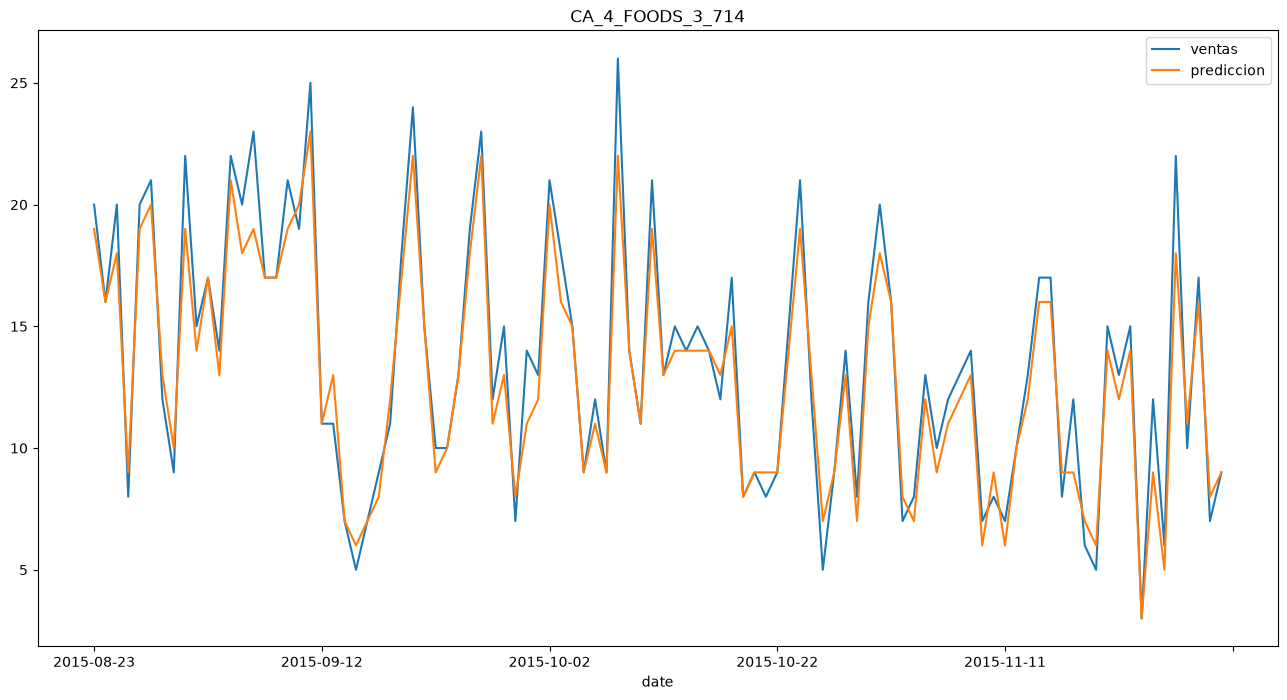

In [27]:
#unificar el df para poder extraer los x e y de cada producto
df =  pd.concat([x,y],axis=1)

for cada in range(0,len(lista_modelos)):

    #Prepara los datos necesarios
    producto = lista_modelos[cada][0]
    modelo = lista_modelos[cada][1]
    variables = modelo[0].feature_names_in_
    target = 'ventas'

    x_prod = df.loc[df.producto == producto].drop(columns=target).copy()
    y_prod = df.loc[df.producto == producto,'ventas'].copy()

    date = x_prod.date.values

    #Genera graficos de predicho vs real
    predicciones = pd.DataFrame(data={'date': date,
                                      'producto': producto,
                                      'ventas': y_prod,
                                      'prediccion': modelo.predict(x_prod[variables])})

    predicciones['prediccion'] = predicciones.prediccion.astype('int')
    predicciones.set_index('date',inplace=True)

    predicciones.tail(100).plot(figsize = (16,8),title = producto);